# Lecture 8: Quantum Circuits with Qiskit

[Course contents](../00_course_contents.md) | [← Previous lecture](./07_bloch_sphere_and_quantum_gates.ipynb) | [Next lecture →](./09_teleportation_and_grover.ipynb) | [Supplementary lecture](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** This notebook may be downloaded, taught, adapted, and shared with attribution. It supports institutional teaching, independent study, examination review, and preparation for quantum-technology roles. See the [reuse terms](../LICENSE), [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and [citation metadata](../CITATION.cff).

## Learning objectives

- Build, visualize, and inspect Qiskit circuits.
- Distinguish exact evolution, finite-shot sampling, modeled noise, and hardware noise.
- Interpret statevector indices and classical result strings correctly.
- Use V2 primitive inputs and results.
- Explain transpilation, dynamic control, and execution cost.

## Core ideas

- **A circuit is an abstract program, not a stored statevector or a hardware pulse schedule.**
- **Bit order must be stated.** Wire order, ket labels, integer indices, and printed classical strings use related but distinct conventions.
- **Execution has layers.** Exact evolution, sampled simulation, noise models, transpilation, and hardware jobs answer different questions.


## Software environment

The course uses the pinned packages in [`requirements.txt`](../requirements.txt). If they are not installed in the active Jupyter kernel, run:

```python
%pip install -r ../requirements.txt
```

Restart the kernel after installation. The next cell contains every library import required by this lecture; the notebook does not depend on variables or imports created by another lecture.

In [1]:
# Complete imports for this lecture.
from IPython.core.interactiveshell import InteractiveShell
import numpy as np
import qiskit
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Operator, Statevector
from qiskit.visualization import array_to_latex, plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
import matplotlib.pyplot as plt
import sympy as sy
import scipy as sp

## Recorded lecture


[Watch "Quantum circuits with Qiskit" on YouTube](https://www.youtube.com/watch?v=X7k4y-Q1yRU).


In [2]:
# Import general libraries

%matplotlib inline

In [3]:
#Activate multiple output
InteractiveShell.ast_node_interactivity = "all"

## Official resources

- [Qiskit SDK guides](https://quantum.cloud.ibm.com/docs/en/guides)
- [Qiskit API reference](https://quantum.cloud.ibm.com/docs/en/api/qiskit)
- [Qiskit source code](https://github.com/Qiskit/qiskit)


Local statevector and shot-based examples need no cloud account. Authentication is required only for the opt-in hardware section, and credentials must remain outside notebooks and version control.


## Environment and installation


Create an isolated environment and install the repository requirements from the project root:

    python -m pip install -r requirements.txt

Do not combine the obsolete standalone qiskit-terra distribution with a modern Qiskit environment. See the [official installation guide](https://quantum.cloud.ibm.com/docs/en/guides/install-qiskit).


Record package versions with experimental results because compiler behavior can change. A requirements or lock file is machine-readable evidence; a package-list screenshot is not an installation specification.


The package-list image below illustrates an older environment. Use it to recognize environment drift, not as installation instructions.

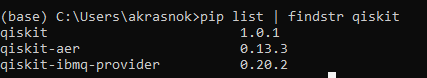


In [4]:
print("Qiskit version:", qiskit.__version__)

Qiskit version: 2.5.2


## Building an abstract circuit

A QuantumCircuit describes logical wires, instructions, parameters, classical storage, and control flow. It is not yet tied to a processor.


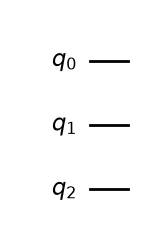

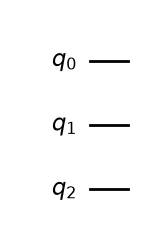

In [5]:
# Create a Quantum Circuit with a quantum register of three qubits
circ = QuantumCircuit(3)

circ.draw('mpl')

*The empty three-qubit diagram contains wires $q_0$, $q_1$, and $q_2$ but no operations, illustrating that circuit construction begins with registers and wires.*


### Adding gates

Gate methods take qubit indices. Controlled-gate methods list the control before the target; circ.cx(1, 2) uses qubit 1 as control and qubit 2 as target.


In [6]:
circ.x(0)
circ.y(1)
circ.z(1)
circ.h(0)
circ.cx(1, 2)  # control q1, target q2

### Drawing a circuit

QuantumCircuit.draw renders the abstract wire order and dependencies. The drawing is not a chip layout or calibrated timing schedule.


In [7]:
circ.draw()

┌───┐┌───┐     
q_0: ┤ X ├┤ H ├─────
     ├───┤├───┤     
q_1: ┤ Y ├┤ Z ├──■──
     └───┘└───┘┌─┴─┐
q_2: ──────────┤ X ├
               └───┘

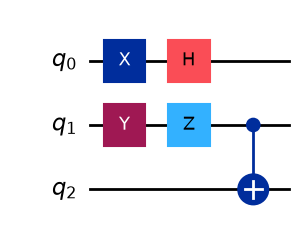

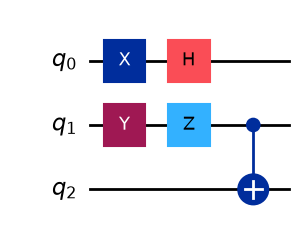

In [8]:
circ.draw("mpl")

*The circuit applies $X$ then $H$ on $q_0$, $Y$ then $Z$ on $q_1$, and a CNOT from $q_1$ to $q_2$; gates in the same vertical layer can act in parallel when hardware permits.*


## Bit order: wires, integers, kets, and strings

Qiskit normally draws $q_0$ at the top, but treats bit 0 as the least significant bit when interpreting integers, kets, and displayed strings:

$$\lvert q_{n-1}\cdots q_1q_0\rangle.$$

Thus $q_2=1,q_1=0,q_0=0$ is written $\lvert100\rangle$, and statevector entry $x$ is the amplitude of the basis state whose binary value is $x$. If measurement maps $q_i$ to $c_i$, the key 10 means $c_1=1,c_0=0$.

In ordered basis $\lvert q_1q_0\rangle=\{\lvert00\rangle,\lvert01\rangle,\lvert10\rangle,\lvert11\rangle\}$, cx(0, 1) has

$$\operatorname{CX}_{0\rightarrow1}=
\begin{bmatrix}
1&0&0&0\\
0&0&0&1\\
0&0&1&0\\
0&1&0&0
\end{bmatrix}.$$

Reversing a circuit drawing changes only the picture. See IBM Quantum, [Bit ordering](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering).

The **Hamming weight** of a computational-basis bit string is the number of entries equal to 1. For example, $\lvert1001010\rangle$ has Hamming weight 3, while its state-vector representation has one nonzero amplitude among $2^7=128$ entries. These are different counts and should not be conflated.


## Exact statevector evolution

Statevector applies an ideal circuit to an explicitly stored pure state. Apart from floating-point roundoff, its amplitudes and probabilities are deterministic: there are no shots and no device-noise model. Generic state storage grows as $2^n$, so statevector evolution is a debugging tool rather than a scalable hardware model.


In [9]:
state = Statevector.from_int(0, 2**3)  # |000>

In [10]:
state.probabilities_dict()

{np.str_('000'): np.float64(1.0)}

In [11]:
state = state.evolve(circ)

In [12]:
state.draw("latex")

<IPython.core.display.Latex object>

In [13]:
array_to_latex(state)

<IPython.core.display.Latex object>

## Bell-state circuit

From $\lvert00\rangle$, a Hadamard on $q_0$ followed by cx(0, 1) prepares

$$\lvert\Phi^+\rangle=\frac{\lvert00\rangle+\lvert11\rangle}{\sqrt2}.$$


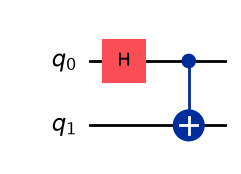

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

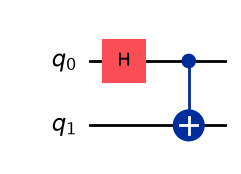

In [14]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
bell.draw("mpl")

bell_input = Statevector.from_int(0, 2**2)
bell_state = bell_input.evolve(bell)
bell_input.draw("latex")
bell_state.draw("latex")

*The Bell circuit applies $H$ to $q_0$ and CNOT from $q_0$ to $q_1$, preparing $(|00\rangle+|11\rangle)/\sqrt{2}$ from $|00\rangle$.*


### Qsphere

A Qsphere is not a multi-qubit Bloch sphere. Each marker represents a computational-basis component; marker size encodes probability and color encodes phase. Basis states are arranged by Hamming weight. Use numerical amplitudes for quantitative work.

Official reference: IBM Quantum, [plot_state_qsphere](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.plot_state_qsphere).


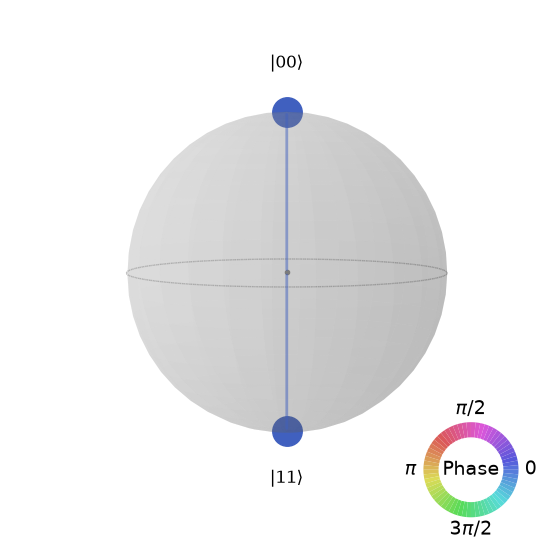

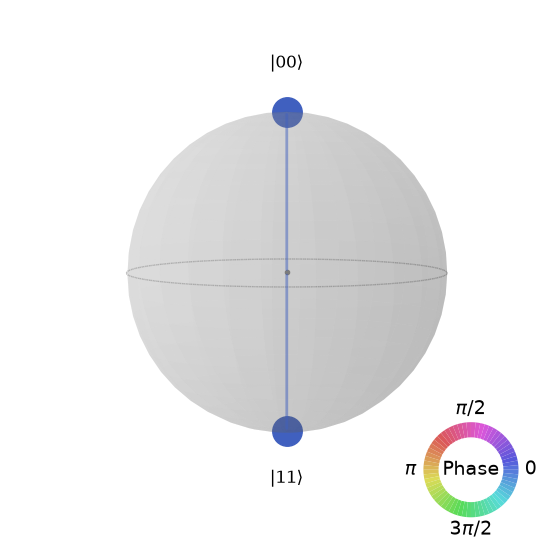

In [15]:
bell_state.draw("qsphere")

*The Qsphere shows equal nonzero amplitudes at $|00\rangle$ and $|11\rangle$ with the same phase, the signature of the prepared $|\Phi^+\rangle$ Bell state.*


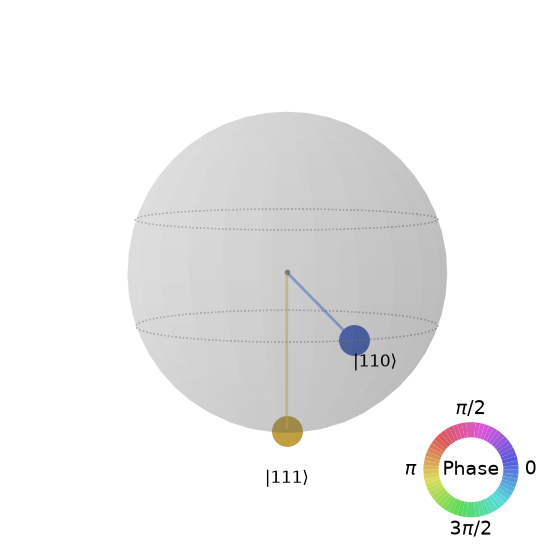

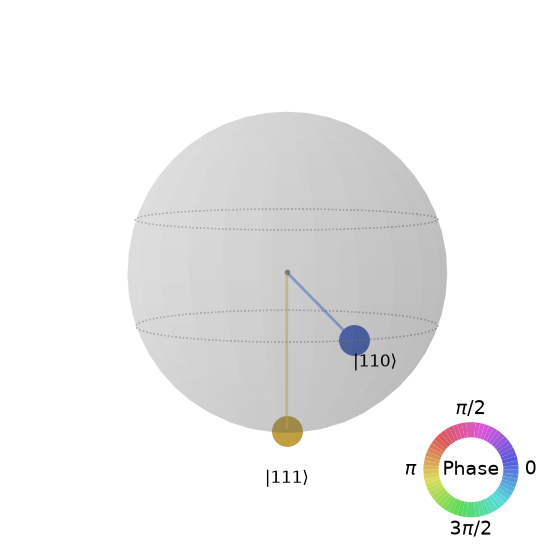

In [16]:
# Qsphere for the earlier three-qubit circuit state
state.draw('qsphere')

*The Qsphere for the earlier three-qubit example displays only its nonzero computational-basis amplitudes; point size encodes probability and color encodes phase.*


## Operator representation

Operator(circuit) constructs the $2^n\times2^n$ matrix only when the circuit is unitary. Matrix storage grows as $4^n$. Measurement, reset, and general control flow are not one unitary on the modeled qubits and require a channel or branch description.


In [17]:
bell_unitary = Operator(bell)
bell_unitary.data

array([[ 0.70710678+0.j,  0.70710678+0.j,  0.        +0.j,
         0.        +0.j],
       [ 0.        +0.j,  0.        +0.j,  0.70710678+0.j,
        -0.70710678+0.j],
       [ 0.        +0.j,  0.        +0.j,  0.70710678+0.j,
         0.70710678+0.j],
       [ 0.70710678+0.j, -0.70710678+0.j,  0.        +0.j,
         0.        +0.j]])

## Greenberger-Horne-Zeilinger state

The circuit below prepares

$$\lvert\mathrm{GHZ}_3\rangle=
\frac{\lvert000\rangle+\lvert111\rangle}{\sqrt2}.$$


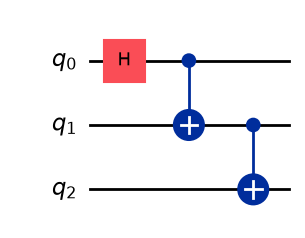

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

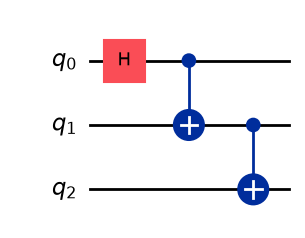

In [18]:
ghz_unitary = QuantumCircuit(3)
ghz_unitary.h(0)
ghz_unitary.cx(0, 1)
ghz_unitary.cx(1, 2)
ghz_unitary.draw("mpl")

ghz_input = Statevector.from_int(0, 2**3)
ghz_state = ghz_input.evolve(ghz_unitary)
ghz_input.draw("latex")
ghz_state.draw("latex")

*The GHZ preparation circuit uses one Hadamard and a chain of two CNOTs to create $(|000\rangle+|111\rangle)/\sqrt{2}$ from $|000\rangle$.*


For $n\ge2$,

$$\lvert\mathrm{GHZ}_n\rangle=
\frac{\lvert0\rangle^{\otimes n}+\lvert1\rangle^{\otimes n}}{\sqrt2}.$$

For $n>2$, this is multipartite entanglement, not a Bell pair shared independently by every pair of qubits.


## Measurement, barriers, and finite shots

A measurement writes a sampled classical outcome. For a binary event of probability $p$, $N$ shots give

$$K\sim\operatorname{Binomial}(N,p),\qquad
\operatorname{SE}(K/N)=\sqrt{\frac{p(1-p)}{N}}.$$

A barrier prevents selected compiler transformations from crossing it. It is not a physical wait and specifies no duration.


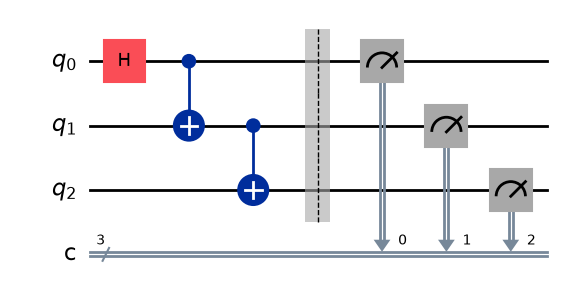

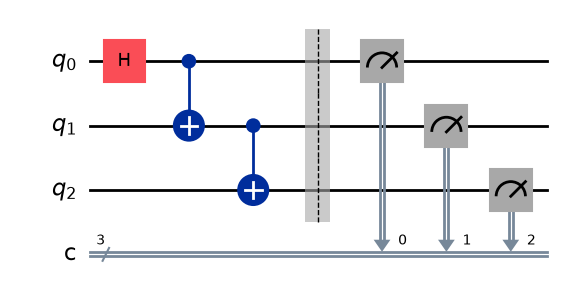

In [19]:
ghz_measured = QuantumCircuit(3, 3)
ghz_measured.h(0)
ghz_measured.cx(0, 1)
ghz_measured.cx(1, 2)
ghz_measured.barrier(range(3))  # compiler boundary, not a delay
ghz_measured.measure(range(3), range(3))
ghz_measured.draw("mpl")

*The measured GHZ circuit adds a barrier and maps each qubit to a classical bit; the barrier is a compiler boundary hint, not a physical gate.*


## V2 primitives: workloads and results


A **Sampler** samples measured classical output registers. A Sampler PUB contains one circuit, optional parameter values, and optionally shots. An **Estimator** accepts a circuit, observables, optional parameter values, and optionally a precision target; its circuit has no final measurements.

Each PUB produces one result. Sampler data contain one BitArray for each named classical register. The manually created register below is named c, whereas measure_all commonly creates meas. StatevectorSampler is a local ideal implementation; Runtime primitives implement the same high-level task on cloud resources. Options and metadata depend on the implementation.

See IBM Quantum, [Primitive inputs and outputs](https://quantum.cloud.ibm.com/docs/en/guides/primitive-input-output).


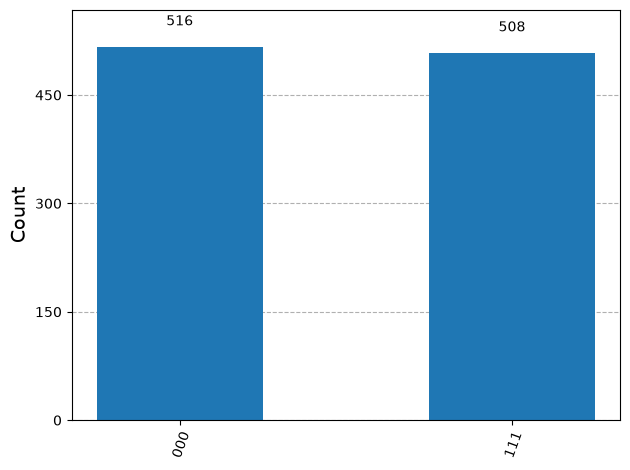

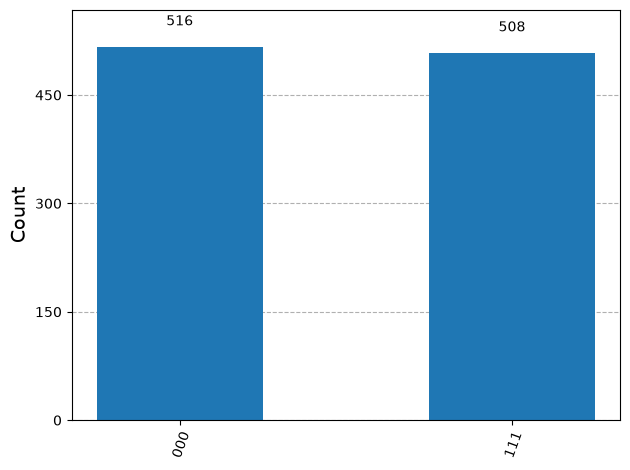

In [20]:
sampler = StatevectorSampler(default_shots=1024, seed=123)
ghz_result = sampler.run([ghz_measured]).result()[0]
ghz_counts = ghz_result.data.c.get_counts()
plot_histogram(ghz_counts)

*The seeded finite-shot histogram contains only $000$ and $111$ with nearly equal counts, as expected for computational-basis measurement of an ideal GHZ state.*


### Sampling randomness is not physical noise

Exact statevector probabilities are deterministic. An ideal Sampler draws a finite random sample from them; its standard error decreases as $1/\sqrt N$. A noise model or physical device instead changes the underlying distribution through imperfect preparation, gates, idling, and readout. More shots reduce sampling uncertainty, not systematic error.

Aer noise models are documented assumptions, not guarantees of hardware fidelity. See [exact SDK simulation](https://quantum.cloud.ibm.com/docs/en/guides/simulate-with-qiskit-sdk-primitives) and [Aer simulation](https://quantum.cloud.ibm.com/docs/en/guides/simulate-with-qiskit-aer).


## Ramsey-style phase-to-population conversion

The sequence $H\,P(\pi/2)\,H$ converts relative phase into computational-basis probability. Starting from $\lvert0\rangle$, this phase gives equal ideal probabilities for 0 and 1.


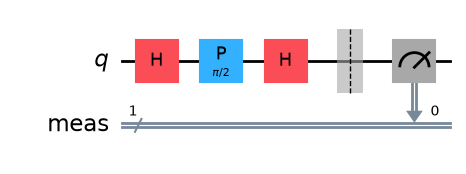

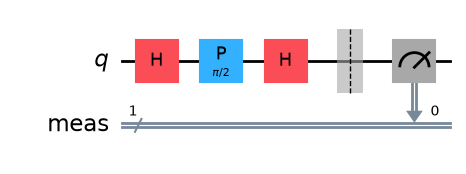

In [21]:
ramsey = QuantumCircuit(1)
ramsey.h(0)
ramsey.p(np.pi / 2, 0)
ramsey.h(0)
ramsey.measure_all()
ramsey.draw("mpl")

*The Ramsey-style circuit applies $H$, a phase rotation $P(\pi/2)$, and a second $H$ before measurement, converting relative phase into a population difference.*


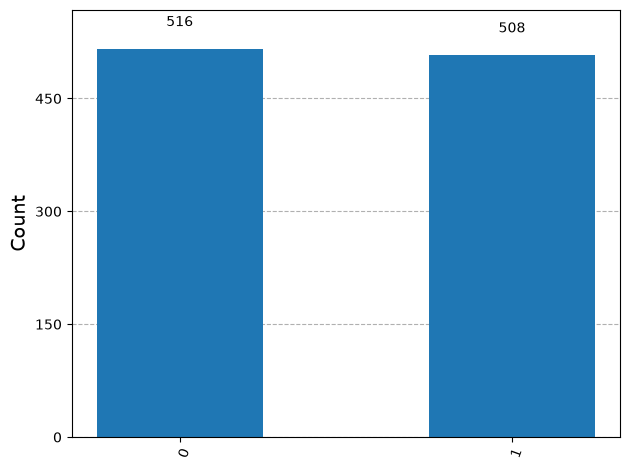

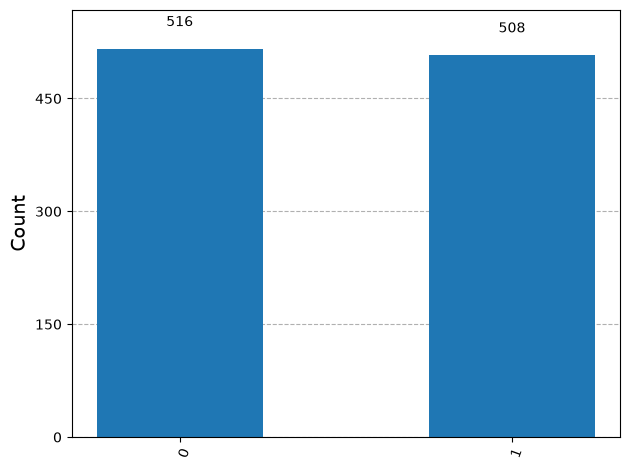

In [22]:
sampler = StatevectorSampler(default_shots=1024, seed=123)
ramsey_result = sampler.run([ramsey]).result()[0]
ramsey_counts = ramsey_result.data.meas.get_counts()
plot_histogram(ramsey_counts)

*The finite-shot histogram estimates the Ramsey circuit's ideal output probabilities; the small count imbalance is sampling variation, not simulated hardware noise.*


## Transpilation and instruction-set compliance

An abstract circuit may use convenient gates and all-to-all interactions. A backend accepts only circuits that obey its Target. Layout maps virtual to physical qubits; routing satisfies connectivity; translation uses supported instructions; optimization rewrites the circuit; optional scheduling assigns times.

The result is an ISA circuit whose instructions and qubit tuples are supported by that target. Transpilation does not simulate noise, and lower gate count does not guarantee lower error. Compare two-qubit count, depth, scheduled duration, layout, and calibration context. Record compiler settings and seeds because heuristic passes can produce different valid circuits.

See IBM Quantum, [Introduction to transpilation](https://quantum.cloud.ibm.com/docs/en/guides/transpile).


## Dynamic circuits and classical feedforward

A dynamic circuit measures during a shot and uses that classical result before the shot ends. This differs from returning a result to a host and submitting another job. Measurement, reset, and feedback add latency and require support from the backend Target.

The example measures a qubit, applies $X$ if the result is 1, and measures again. Ideally the final result is always 0.


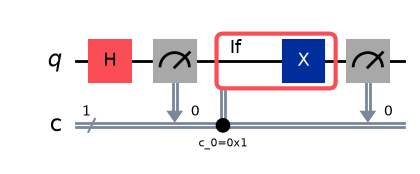

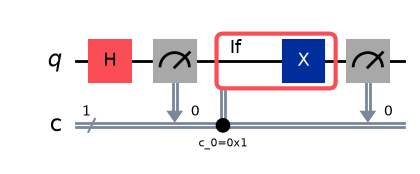

In [23]:
dynamic = QuantumCircuit(1, 1)
dynamic.h(0)
dynamic.measure(0, 0)
with dynamic.if_test((dynamic.clbits[0], 1)):
    dynamic.x(0)
dynamic.measure(0, 0)
dynamic.draw("mpl")

*The dynamic circuit measures after a Hadamard, conditionally applies $X$ when the classical result is 1, and measures again; ideal feedforward drives the final result to 0.*


See IBM Quantum, [Classical feedforward and control flow](https://quantum.cloud.ibm.com/docs/en/guides/classical-feedforward-and-control-flow).


## Execution time, usage, and experimental cost

Compilation time, queue delay, wall-clock turnaround, scheduled duration, and QPU usage are different quantities. A useful conceptual estimate is

$$T_{\mathrm{usage}}\approx T_{\mathrm{overhead}}+
N_{\mathrm{exec}}\bigl(t_{\mathrm{repetition}}+t_{\mathrm{circuit}}\bigr),$$

where $N_{\mathrm{exec}}$ includes shots and circuits generated by parameter broadcasting, observable grouping, or mitigation. Dynamic measurement can increase circuit duration even when it reduces coherent depth. Bundle compatible parameter sweeps, choose shots from a precision target, and record actual usage metadata. Accounting rules and prices can change.

See IBM Quantum, [Execution modes](https://quantum.cloud.ibm.com/docs/en/guides/execution-modes) and [Workload usage](https://quantum.cloud.ibm.com/docs/en/guides/estimate-job-run-time).


## Optional hardware execution

Hardware execution has four stages: select a backend, transpile to its ISA, execute a primitive workload, and interpret results with metadata. Never place a token in a notebook or Git repository. Configure credentials outside the project. The executable cell is disabled by default.


In [24]:
RUN_ON_HARDWARE = False

if RUN_ON_HARDWARE:
    service = QiskitRuntimeService()
    hardware_backend = service.least_busy(
        operational=True,
        simulator=False,
        min_num_qubits=ramsey.num_qubits,
    )
    pass_manager = generate_preset_pass_manager(
        backend=hardware_backend,
        optimization_level=1,
        seed_transpiler=123,
    )
    ramsey_isa = pass_manager.run(ramsey)

    hardware_sampler = SamplerV2(mode=hardware_backend)
    hardware_job = hardware_sampler.run([ramsey_isa], shots=1024)
    hardware_result = hardware_job.result()[0]
    hardware_counts = hardware_result.data.meas.get_counts()
    display(plot_histogram(hardware_counts))
else:
    print("Hardware execution skipped.")

Hardware execution skipped.


### Retrieve and audit a previous job

Store the job ID, backend identity, PUB inputs, compiler settings, and relevant calibration and usage metadata with an experiment record. Do not store credentials. With an authenticated service, retrieve a known job with service.job("YOUR_JOB_ID").


## Key takeaways

- Use `Statevector` or `Operator` for exact ideal analysis and V2 primitives for sampled workloads.
- Interpret every count key using the circuit's classical-register and bit-order conventions.
- Transpilation maps a logical circuit to the target instruction set and connectivity; the result can differ substantially from the source circuit.
- Dynamic circuits combine measurement with real-time classical feedforward, subject to backend support and timing limits.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. IBM Quantum, [Install Qiskit](https://quantum.cloud.ibm.com/docs/en/guides/install-qiskit).
2. IBM Quantum, [Bit ordering](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering).
3. IBM Quantum, [Primitive inputs and outputs](https://quantum.cloud.ibm.com/docs/en/guides/primitive-input-output).
4. IBM Quantum, [Exact SDK simulation](https://quantum.cloud.ibm.com/docs/en/guides/simulate-with-qiskit-sdk-primitives).
5. IBM Quantum, [Aer simulation](https://quantum.cloud.ibm.com/docs/en/guides/simulate-with-qiskit-aer).
6. IBM Quantum, [Introduction to transpilation](https://quantum.cloud.ibm.com/docs/en/guides/transpile).
7. IBM Quantum, [Classical feedforward and control flow](https://quantum.cloud.ibm.com/docs/en/guides/classical-feedforward-and-control-flow).
8. IBM Quantum, [Execution modes](https://quantum.cloud.ibm.com/docs/en/guides/execution-modes) and [Workload usage](https://quantum.cloud.ibm.com/docs/en/guides/estimate-job-run-time).
9. [Qiskit source repository](https://github.com/Qiskit/qiskit).
